In [1]:
import mne
import pickle
import hashlib
import pathlib

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import ConfusionMatrixDisplay
from sklearn.model_selection import train_test_split

from models.EEGNet import EEGNet, train_eegnet
from models.GATGRU import train_gat_gru_transformer, channel_importance, band_importance, gat_attention, plv_report
from scripts.dataset_manager import read_raw_dataset

# Feature extraction

In [2]:
EPOCH_DATASET_NAME = pathlib.Path('data/epoch_dataset')
EPOCH_DATASET_LIGHT_NAME = pathlib.Path('data/epoch_dataset_light')
EPOCH_FILTERED_DATASET_NAME = pathlib.Path('data/epoch_dataset_filtered')

def merge_epochs_dict(epochs_dict):
    """Merges the dict of epochs into a single epoch object, preserving subject and session identification in the metadata."""
    all_epochs = []

    for subj, sessions in epochs_dict.items():
        for sess, ep in sessions.items():
            ep = ep.copy()

            # build/extend metadata with subject + session
            n = len(ep)
            extra = pd.DataFrame(
                {"subject": [subj] * n, "session": [sess] * n},
                index=ep.metadata.index if ep.metadata is not None else range(n),
            )

            if ep.metadata is None:
                ep.metadata = extra
            else:
                # avoid clobbering if these columns already exist
                meta = ep.metadata.copy()
                meta["subject"] = subj
                meta["session"] = sess
                ep.metadata = meta

            all_epochs.append(ep)

    merged = mne.concatenate_epochs(all_epochs)
    return merged

def query_epochs(epochs, query):
    ep = epochs.copy()
    keep_idx = ep.metadata.query(query).index
    mask = ep.metadata.index.isin(keep_idx)
    return ep[mask]

epoch_dict = read_raw_dataset(EPOCH_FILTERED_DATASET_NAME)
epochs = merge_epochs_dict(epoch_dict)
epochs_scaled = epochs.copy()
epochs_scaled.load_data().apply_function(
    lambda x: (x - x.mean()) / (x.std() + 1e-12), channel_wise=True
)

# normal data
filtered_epochs = query_epochs(epochs, "((EventType == 'PinchLog') & (PinchType == 'PINCH')) | (EventType == 'NoPinchLog')").copy()
filtered_epochs_scaled = query_epochs(epochs_scaled, "((EventType == 'PinchLog') & (PinchType == 'PINCH')) | (EventType == 'NoPinchLog')").copy()

# GAZE as hard negatives
filtered_epochs_gaze = query_epochs(epochs, "((EventType == 'PinchLog') & ((PinchType == 'PINCH') | (PinchType == 'GAZE'))) | (EventType == 'NoPinchLog')").copy()
filtered_epochs_gaze_scaled = query_epochs(epochs_scaled, "((EventType == 'PinchLog') & ((PinchType == 'PINCH') | (PinchType == 'GAZE'))) | (EventType == 'NoPinchLog')").copy()
filtered_epochs_gaze.metadata.loc[:, 'OriginalEventType'] = filtered_epochs_gaze.metadata.loc[:, 'EventType']
filtered_epochs_gaze.metadata.loc[filtered_epochs_gaze.metadata.PinchType == 'GAZE', 'EventType'] = "NoPinchLog"
filtered_epochs_gaze_scaled.metadata.loc[:, 'OriginalEventType'] = filtered_epochs_gaze_scaled.metadata.loc[:, 'EventType']
filtered_epochs_gaze_scaled.metadata.loc[filtered_epochs_gaze_scaled.metadata.PinchType == 'GAZE', 'EventType'] = "NoPinchLog"

# PINCH_WIZARD_OF_OZ as pinches
filtered_epochs_hinted = query_epochs(epochs, "((EventType == 'PinchLog') & ((PinchType == 'PINCH') | (PinchType == 'PINCH_WIZARD_OF_OZ'))) | (EventType == 'NoPinchLog')").copy()
filtered_epochs_hinted_scaled = query_epochs(epochs_scaled, "((EventType == 'PinchLog') & ((PinchType == 'PINCH') | (PinchType == 'PINCH_WIZARD_OF_OZ'))) | (EventType == 'NoPinchLog')").copy()
filtered_epochs_hinted.metadata.loc[:, 'OriginalPinchType'] = filtered_epochs_hinted.metadata.loc[:, 'PinchType']
filtered_epochs_hinted.metadata.loc[filtered_epochs_hinted.metadata.PinchType == 'PINCH_WIZARD_OF_OZ', 'PinchType'] = "PINCH"
filtered_epochs_hinted_scaled.metadata.loc[:, 'OriginalPinchType'] = filtered_epochs_hinted_scaled.metadata.loc[:, 'PinchType']
filtered_epochs_hinted_scaled.metadata.loc[filtered_epochs_hinted_scaled.metadata.PinchType == 'PINCH_WIZARD_OF_OZ', 'PinchType'] = "PINCH"

# PINCH_IGNORED as pinches
filtered_epochs_ignored = query_epochs(epochs, "((EventType == 'PinchLog') & ((PinchType == 'PINCH') | (PinchType == 'PINCH_IGNORED'))) | (EventType == 'NoPinchLog')").copy()
filtered_epochs_ignored_scaled = query_epochs(epochs_scaled, "((EventType == 'PinchLog') & ((PinchType == 'PINCH') | (PinchType == 'PINCH_IGNORED'))) | (EventType == 'NoPinchLog')").copy()
filtered_epochs_ignored.metadata.loc[:, 'OriginalPinchType'] = filtered_epochs_ignored.metadata.loc[:, 'PinchType']
filtered_epochs_ignored.metadata.loc[filtered_epochs_ignored.metadata.PinchType == 'PINCH_IGNORED', 'PinchType'] = "PINCH"
filtered_epochs_ignored_scaled.metadata.loc[:, 'OriginalPinchType'] = filtered_epochs_ignored_scaled.metadata.loc[:, 'PinchType']
filtered_epochs_ignored_scaled.metadata.loc[filtered_epochs_ignored_scaled.metadata.PinchType == 'PINCH_IGNORED', 'PinchType'] = "PINCH"


Reading C:\Users\nicol\github\VIBE\DataAnalysis\data\epoch_dataset_filtered\subject_21\session_1\session-epo.fif ...
    Found the data of interest:
        t =   -1700.00 ...     300.00 ms
        0 CTF compensation matrices available
Adding metadata with 52 columns
264 matching events found
No baseline correction applied
0 projection items activated
Reading C:\Users\nicol\github\VIBE\DataAnalysis\data\epoch_dataset_filtered\subject_21\session_2\session-epo.fif ...
    Found the data of interest:
        t =   -1700.00 ...     300.00 ms
        0 CTF compensation matrices available
Adding metadata with 52 columns
124 matching events found
No baseline correction applied
0 projection items activated
Reading C:\Users\nicol\github\VIBE\DataAnalysis\data\epoch_dataset_filtered\subject_22\session_1\session-epo.fif ...
    Found the data of interest:
        t =   -1700.00 ...     300.00 ms
        0 CTF compensation matrices available
Adding metadata with 52 columns
185 matching events foun

C:\Users\nicol\AppData\Local\Temp\ipykernel_6456\2234858583.py:31: RuntimeWarning: Concatenation of Annotations within Epochs is not supported yet. All annotations will be dropped.
  merged = mne.concatenate_epochs(all_epochs)


### Result caching

Model-training runs below are expensive, so their results are cached on disk in `RESULTS_DIR`, keyed by a run name and annotated with `DATA_VERSION` - a fingerprint of the input dataset (`EPOCH_FILTERED_DATASET_NAME`, the directory `read_raw_dataset` above loads from). If a cached result's `data_version` matches the current one, it is loaded instead of retraining. Set `FORCE_RECOMPUTE_RESULTS = True` (or pass `force=True` to `run_cached`) to ignore the cache and recompute everything.

In [3]:
RESULTS_DIR = pathlib.Path('data/results')
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

FORCE_RECOMPUTE_RESULTS = True  # set True to ignore cached results and recompute everything


def compute_data_version(dataset_path: pathlib.Path) -> str:
    """Fingerprints a dataset directory so cached run results can be invalidated when the
    underlying input data changes. Uses (relative path, size, mtime) per file rather than
    hashing file contents, since the dataset is hundreds of MB."""
    dataset_path = pathlib.Path(dataset_path)
    entries = []
    for f in sorted(dataset_path.rglob('*')):
        if f.is_file():
            stat = f.stat()
            entries.append(f"{f.relative_to(dataset_path).as_posix()}:{stat.st_size}:{int(stat.st_mtime_ns)}")
    return hashlib.sha256("\n".join(entries).encode()).hexdigest()[:16]


DATA_VERSION = compute_data_version(EPOCH_FILTERED_DATASET_NAME)


def run_cached(name: str, compute_fn, data_version: str = None, force: bool = None):
    """Runs `compute_fn()` and caches the result under `name` in RESULTS_DIR, annotated with
    `data_version` (defaults to the global DATA_VERSION). On a later call with the same name
    and data_version, the cached result is loaded instead of recomputing. Pass force=True (or
    set FORCE_RECOMPUTE_RESULTS) to always recompute and overwrite the cache."""
    data_version = DATA_VERSION if data_version is None else data_version
    force = FORCE_RECOMPUTE_RESULTS if force is None else force
    cache_path = RESULTS_DIR / f"{name}.pkl"

    if not force and cache_path.exists():
        with open(cache_path, "rb") as fh:
            cached = pickle.load(fh)
        if cached.get("data_version") == data_version:
            print(f"[{name}] loaded cached result (data_version={data_version})")
            return cached["result"]
        print(f"[{name}] cached data_version={cached.get('data_version')} != {data_version}, recomputing")
    else:
        print(f"[{name}] {'forced recompute' if force else 'no cache found'}, running...")

    result = compute_fn()
    with open(cache_path, "wb") as fh:
        pickle.dump({"data_version": data_version, "result": result}, fh)
    return result


# Model training & inference

## Random Forest

Input:

--------------------------------------------------------------------------
FILTERING AND BASELINE ARE PARADIGM-SPECIFIC
--------------------------------------------------------------------------

```
  paradigm   high-pass      low-pass   epoch          baseline
  --------   -----------    --------   ------------   -------------------------
  MI         0.5-4 Hz       40 Hz      0.5 .. 3.5 s   none (log-power handles it)
  P300       0.1-0.5 Hz     20 Hz      -0.2 .. 0.8 s  -0.2 .. 0 s
  SPN        <= 0.05 Hz !   20-30 Hz   -2.0 .. 0.5 s  cue-locked, NOT -0.2..0 s !
  ErrP       0.1-1 Hz       20 Hz      -0.2 .. 0.8 s  -0.2 .. 0 s
```

## EEGNet

This is an implementation of EEGNet according to the original paper (Lawhern et al., 2018) in PyTorch.

Input: The EEGNet takes the raw measurements as inputs.

In [7]:
# region EEGNet



def _get_history_dict(history):
    """Support Keras History objects or plain dicts of lists."""
    return history.history if hasattr(history, "history") else history

def _chance_level(result):
    """
    Estimate the baseline accuracy using the majority-class baseline.
    """
    cm = np.asarray(result["confusion_matrix"])
    true_class_counts = cm.sum(axis=1)  # rows = true labels
    total = true_class_counts.sum()
    return true_class_counts.max() / total


def plot_run(result, run_name="run", save_path=None):
    """Plot loss/accuracy curves and confusion matrix for a single run."""
    hist = _get_history_dict(result["history"])
    n_epochs = len(next(iter(hist.values())))
    epochs = range(1, n_epochs + 1)

    fig, axes = plt.subplots(1, 3, figsize=(16, 4))
    fig.suptitle(
        f"{run_name} — test acc: {result['test_accuracy']:.3f}, "
        f"test loss: {result['test_loss']:.3f}"
    )

    # Loss curves
    ax = axes[0]
    if "loss" in hist:
        ax.plot(epochs, hist["loss"], label="train")
    if "val_loss" in hist:
        ax.plot(epochs, hist["val_loss"], label="val")
    ax.set_title("Loss")
    ax.set_xlabel("Epoch")
    ax.legend()

    # Accuracy curves
    ax = axes[1]
    acc_key = "accuracy" if "accuracy" in hist else "acc"
    val_acc_key = "val_accuracy" if "val_accuracy" in hist else "val_acc"
    if acc_key in hist:
        ax.plot(epochs, hist[acc_key], label="train")
    if val_acc_key in hist:
        ax.plot(epochs, hist[val_acc_key], label="val")

    chance = _chance_level(result)
    ax.axhline(
        chance, color="gray", linestyle="--", linewidth=1.5,
        label=f"chance ({chance:.2f})",
    )

    ax.set_title("Accuracy")
    ax.set_xlabel("Epoch")
    ax.legend()

    # Confusion matrix
    ax = axes[2]
    disp = ConfusionMatrixDisplay(
        confusion_matrix=result["confusion_matrix"],
        display_labels=result["classes"],
    )
    disp.plot(ax=ax, colorbar=False, cmap="Blues")
    ax.set_title("Confusion matrix")

    plt.tight_layout()
    if save_path:
        fig.savefig(save_path, dpi=150, bbox_inches="tight")
    return fig

# endregion

### Comparing cross subject vs cross session

In [8]:
def classify_general(data):
    X_train_idx, X_test_idx, y_train, y_test = train_test_split(np.arange(len(data)), data.metadata.EventType, test_size=.2)
    X_train, X_test = data[X_train_idx], data[X_test_idx]

    return train_eegnet(X_train, y_train, X_test, y_test, run_name="eegnet-general", wandb_group="EEGNet"), X_test.metadata

def classify_cross_subject(data, leave_out='', ignore=''):
    train_subjects, test_subjects = train_test_split(data.metadata["subject"].unique().tolist())
    if leave_out != '':
        train_subjects = data.metadata["subject"].unique().tolist()
        train_subjects.remove(leave_out)
        test_subjects = [leave_out]
    if ignore != '':
        train_subjects.remove(ignore)

    print(f"{len(train_subjects)} train subjects, {len(test_subjects)} test subjects")

    train_epochs = query_epochs(data, f"subject in {train_subjects}")
    test_epochs = query_epochs(data, f"subject in {test_subjects}")

    return train_eegnet(train_epochs, train_epochs.metadata.EventType, test_epochs, test_epochs.metadata.EventType, run_name="eegnet-cross_subject", wandb_group="EEGNet", n_epochs=150), test_epochs.metadata

def classify_cross_session(data):
    train_epochs = query_epochs(data, f"session == 'session_1'")
    test_epochs = query_epochs(data, f"session == 'session_2'")

    return train_eegnet(train_epochs, train_epochs.metadata.EventType, test_epochs, test_epochs.metadata.EventType, run_name="eegnet-cross_session", wandb_group="EEGNet", n_epochs=100), test_epochs.metadata

def classify_leave_one_out(data):
    results = {}
    for subject in data.metadata["subject"].unique().tolist():
        result, meta = classify_cross_subject(data, leave_out=subject)
        results[subject] = {
            "result": result,
            "test_metadata": meta
        }
    return results

def classify_leave_one_out_and_test_others(data):
    results = {}
    subjects = data.metadata["subject"].unique().tolist()
    for s in subjects:
        results[s] = {}
        for t in subjects:
            if s == t:
                continue
            result, meta = classify_cross_subject(data, leave_out=s, ignore=t)
            results[s][t] = {
                "result": result,
                "test_metadata": meta
            }
    return results

results_general, results_general_meta = run_cached(
    "eegnet_general_run", lambda: classify_general(filtered_epochs_scaled)
)
results_cross_subject, results_cross_subject_meta = run_cached(
    "eegnet_cross_subject_run", lambda: classify_cross_subject(filtered_epochs_scaled, leave_out='subject_32')
)
results_cross_session, results_cross_session_meta = run_cached(
    "eegnet_cross_session_run", lambda: classify_cross_session(filtered_epochs_scaled)
)
results_leave_one_out = run_cached(
    "eegnet_leave_one_out_run", lambda: classify_leave_one_out(filtered_epochs_scaled)
)
results_leave_one_out1 = run_cached(
    "eegnet_leave_one_out_gaze_run", lambda: classify_leave_one_out(filtered_epochs_gaze_scaled)
)
results_leave_one_out2 = run_cached(
    "eegnet_leave_one_out_hinted_run", lambda: classify_leave_one_out(filtered_epochs_hinted_scaled)
)
results_leave_one_out3 = run_cached(
    "eegnet_leave_one_out_ignored_run", lambda: classify_leave_one_out(filtered_epochs_ignored_scaled)
)
# classify_leave_one_out4 = run_cached(
#     "classify_leave_one_out4", lambda: classify_leave_one_out_and_test_others(filtered_epochs_scaled)
# )

[eegnet_general_run] forced recompute, running...
EEGNet-8,2 | 20 ch x 601 samples | 2 classes | 2690 trainable params | device=cuda


wandb: setting up run 7oszzmt7
wandb: Tracking run with wandb version 0.30.0
wandb: Run data is saved locally in C:\Users\nicol\github\VIBE\DataAnalysis\wandb\run-20260921_173809-7oszzmt7
wandb: Run `wandb offline` to turn off syncing.
wandb: Syncing run eegnet-general
wandb:  View project at https://wandb.ai/nbaeriswyl-eth-z-rich/eeg-pinch-classification
wandb:  View run at https://wandb.ai/nbaeriswyl-eth-z-rich/eeg-pinch-classification/runs/7oszzmt7


epoch    1/100  loss 0.6942  acc 0.523  val_loss 0.6869  val_acc 0.556
epoch   10/100  loss 0.6079  acc 0.680  val_loss 0.6310  val_acc 0.644
epoch   20/100  loss 0.5737  acc 0.707  val_loss 0.6304  val_acc 0.644
epoch   30/100  loss 0.5475  acc 0.723  val_loss 0.6124  val_acc 0.653
epoch   40/100  loss 0.5268  acc 0.738  val_loss 0.6066  val_acc 0.654
epoch   50/100  loss 0.5158  acc 0.745  val_loss 0.6067  val_acc 0.661
epoch   60/100  loss 0.5116  acc 0.748  val_loss 0.6147  val_acc 0.664
epoch   70/100  loss 0.5035  acc 0.758  val_loss 0.6187  val_acc 0.663
epoch   80/100  loss 0.4925  acc 0.763  val_loss 0.6309  val_acc 0.644
epoch   90/100  loss 0.4936  acc 0.757  val_loss 0.6171  val_acc 0.660
epoch  100/100  loss 0.4850  acc 0.762  val_loss 0.6227  val_acc 0.667

Test loss 0.5888 | test accuracy 0.6951
Confusion matrix (rows = true, cols = predicted):
[[339 146]
 [122 272]]


wandb: updating run metadata; uploading artifact run-7oszzmt7-testconfusion_matrix_table-WTrmow
wandb: uploading artifact run-7oszzmt7-testconfusion_matrix_table-WTrmow
wandb: uploading history steps 95-99, summary
wandb: 
wandb: Run history:
wandb:  train/acc ▁▂▄▄▅▅▅▅▅▅▆▆▆▆▆▇▇▇▇▆▇▇▇▇▇▇▇▇▇▇▇▇▇▇▇███▇█
wandb: train/loss █▇▇▇▆▅▅▅▅▅▄▄▄▄▃▃▃▃▃▃▃▃▂▂▂▂▂▂▂▂▁▁▂▂▁▁▁▂▁▁
wandb:    val/acc ▁▄▅▆▆▆▆▆▇█▇█▇▇▇█▇█▇▇▇▇▇▇██▇▇▆▇▆▇██▇▇▇██▆
wandb:   val/loss █▆▅▅▄▄▅▃▃▂▂▂▂▂▁▂▂▁▁▂▂▃▂▃▃▃▃▅▃▃▃▄▃▃▂▃▃▃▃▂
wandb: 
wandb: Run summary:
wandb: test/accuracy 0.69511
wandb:     test/loss 0.58878
wandb:     train/acc 0.76245
wandb:    train/loss 0.48503
wandb:       val/acc 0.66714
wandb:      val/loss 0.62267
wandb: 
wandb:  View run eegnet-general at: https://wandb.ai/nbaeriswyl-eth-z-rich/eeg-pinch-classification/runs/7oszzmt7
wandb:  View project at: https://wandb.ai/nbaeriswyl-eth-z-rich/eeg-pinch-classification
wandb: Synced 4 W&B file(s), 1 media file(s), 2 artifact file(s) and 0 other file(s)
wandb: Find logs at: .\

[eegnet_cross_subject_run] forced recompute, running...
13 train subjects, 1 test subjects
EEGNet-8,2 | 20 ch x 601 samples | 2 classes | 2690 trainable params | device=cuda


...

wandb: updating run metadata; uploading artifact run-2ln5z0xf-testconfusion_matrix_table-18vmVg
wandb: uploading artifact run-2ln5z0xf-testconfusion_matrix_table-18vmVg
wandb: uploading wandb-summary.json; uploading config.yaml
wandb: uploading history steps 119-149, summary
wandb: 
wandb: Run history:
wandb:  train/acc ▁▁▂▂▂▃▃▄▄▅▆▅▅▆▆▆▆▆▆▇▇▇▇▇▇▇████▇▇██████▇█
wandb: train/loss █▇▇▇▆▅▅▅▄▄▄▃▃▃▃▃▂▂▂▂▂▂▂▂▂▂▂▂▁▁▂▂▁▁▂▁▁▁▁▂
wandb:    val/acc ▁▃▃▃▄▄▄▅▅▅▆▆▅▅▆▆▇▇▆▆▇▆▆▆▆▇▆▇▇▆▇▇▇█▇█▇▇██
wandb:   val/loss ██▇▆▆▅▅▅▄▄▃▃▃▃▃▂▂▂▂▂▃▁▁▁▁▁▁▁▂▁▃▁▂▂▂▂▁▂▁▂
wandb: 
wandb: Run summary:
wandb: test/accuracy 0.5791
wandb:     test/loss 0.74328
wandb:     train/acc 0.77523
wandb:    train/loss 0.46233
wandb:       val/acc 0.69836
wandb:      val/loss 0.58568
wandb: 
wandb:  View run eegnet-cross_subject at: https://wandb.ai/nbaeriswyl-eth-z-rich/eeg-pinch-classification/runs/2ln5z0xf
wandb:  View project at: https://wandb.ai/nbaeriswyl-eth-z-rich/eeg-pinch-classification
wandb: Synced 4 W&B file(s), 1 media file(

13 train subjects, 1 test subjects
EEGNet-8,2 | 20 ch x 601 samples | 2 classes | 2690 trainable params | device=cuda


wandb: setting up run rykutqv9
wandb: Tracking run with wandb version 0.30.0
wandb: Run data is saved locally in C:\Users\nicol\github\VIBE\DataAnalysis\wandb\run-20260921_183833-rykutqv9
wandb: Run `wandb offline` to turn off syncing.
wandb: Syncing run eegnet-cross_subject
wandb:  View project at https://wandb.ai/nbaeriswyl-eth-z-rich/eeg-pinch-classification
wandb:  View run at https://wandb.ai/nbaeriswyl-eth-z-rich/eeg-pinch-classification/runs/rykutqv9


epoch    1/150  loss 0.6925  acc 0.541  val_loss 0.6853  val_acc 0.554
epoch   10/150  loss 0.6205  acc 0.653  val_loss 0.6438  val_acc 0.626
epoch   20/150  loss 0.5755  acc 0.695  val_loss 0.6094  val_acc 0.685
epoch   30/150  loss 0.5337  acc 0.728  val_loss 0.5987  val_acc 0.665
epoch   40/150  loss 0.5155  acc 0.738  val_loss 0.5884  val_acc 0.684
epoch   50/150  loss 0.5013  acc 0.748  val_loss 0.5949  val_acc 0.673
epoch   60/150  loss 0.4916  acc 0.761  val_loss 0.5963  val_acc 0.678
epoch   70/150  loss 0.4876  acc 0.763  val_loss 0.6023  val_acc 0.673
epoch   80/150  loss 0.4666  acc 0.777  val_loss 0.6016  val_acc 0.666
epoch   90/150  loss 0.4687  acc 0.777  val_loss 0.6011  val_acc 0.693
epoch  100/150  loss 0.4706  acc 0.770  val_loss 0.6133  val_acc 0.681
epoch  110/150  loss 0.4632  acc 0.778  val_loss 0.5999  val_acc 0.691
epoch  120/150  loss 0.4691  acc 0.775  val_loss 0.6079  val_acc 0.687
epoch  130/150  loss 0.4634  acc 0.780  val_loss 0.5971  val_acc 0.693
epoch 

wandb: updating run metadata; uploading artifact run-rykutqv9-testconfusion_matrix_table-PcSspQ
wandb: uploading artifact run-rykutqv9-testconfusion_matrix_table-PcSspQ
wandb: uploading wandb-summary.json; uploading config.yaml
wandb: 
wandb: Run history:
wandb:  train/acc ▁▁▃▃▃▅▅▅▅▅▆▆▇▆▆▇▇▇▇▇▇██▇█▇▇████▇████████
wandb: train/loss █▇▇▇▆▆▆▅▅▅▄▄▄▃▃▃▃▃▃▂▂▂▂▂▂▁▁▂▂▁▁▁▁▁▁▁▁▁▁▁
wandb:    val/acc ▁▂▃▄▅▇▆▆▅▆▆▇▅▇▇▇▆▆▆▆▇▆▇▆▇▇▆█▇▆▆█▆▆▇▇▆▇▆▇
wandb:   val/loss █▇▅▅▄▃▃▂▂▂▁▃▂▃▂▂▁▁▂▂▃▂▂▂▂▂▂▃▃▂▃▂▂▂▂▃▄▃▃▃
wandb: 
wandb: Run summary:
wandb: test/accuracy 0.63588
wandb:     test/loss 0.67578
wandb:     train/acc 0.78601
wandb:    train/loss 0.45702
wandb:       val/acc 0.68595
wandb:      val/loss 0.60569
wandb: 
wandb:  View run eegnet-cross_subject at: https://wandb.ai/nbaeriswyl-eth-z-rich/eeg-pinch-classification/runs/rykutqv9
wandb:  View project at: https://wandb.ai/nbaeriswyl-eth-z-rich/eeg-pinch-classification
wandb: Synced 4 W&B file(s), 1 media file(s), 2 artifact file(s) and 0 other file(s)
wand

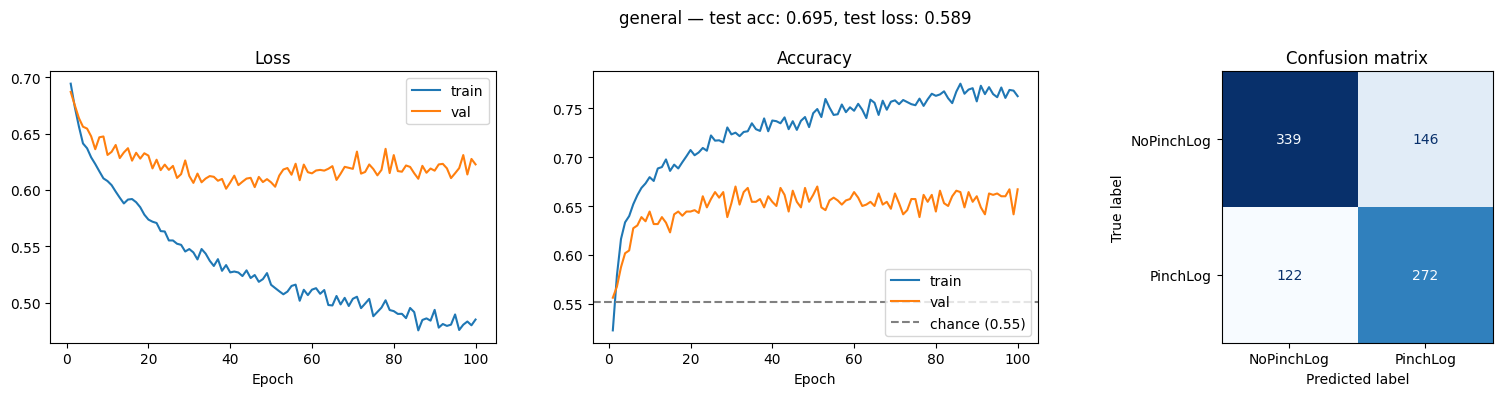

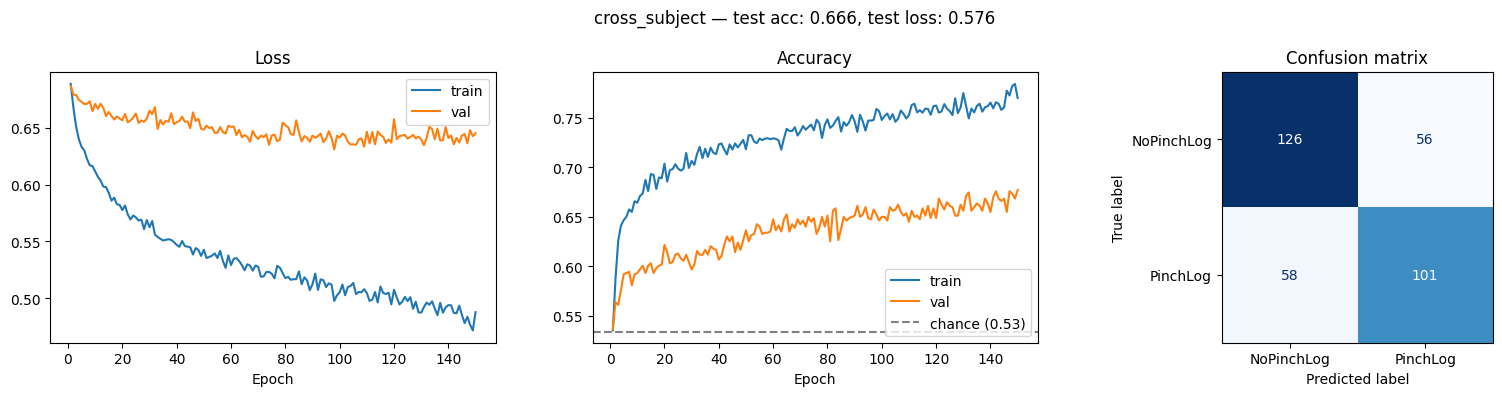

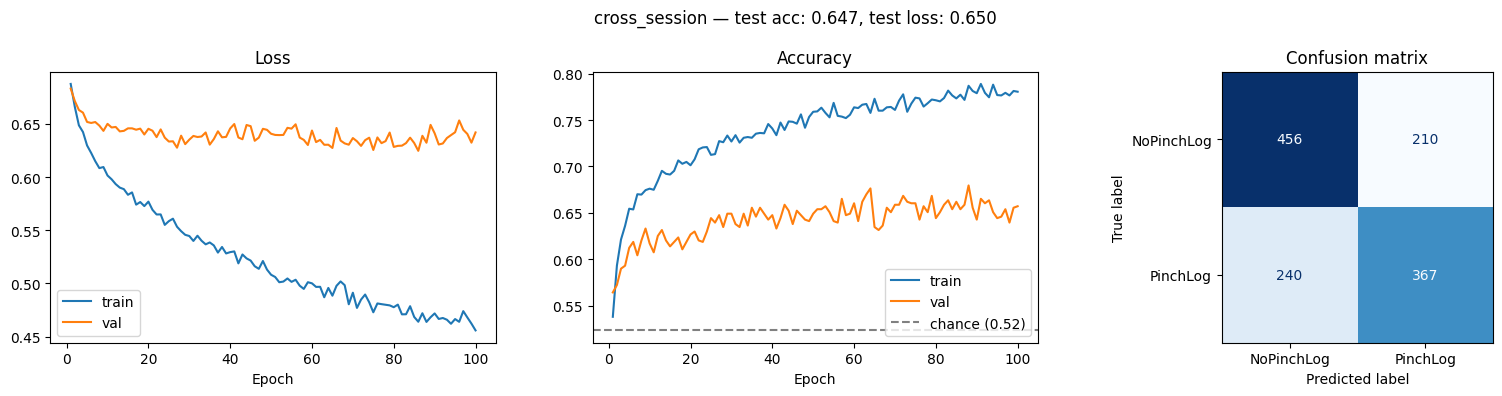

In [9]:
_ = plot_run(results_general, run_name="general")
_ = plot_run(results_cross_subject, run_name="cross_subject")
_ = plot_run(results_cross_session, run_name="cross_session")

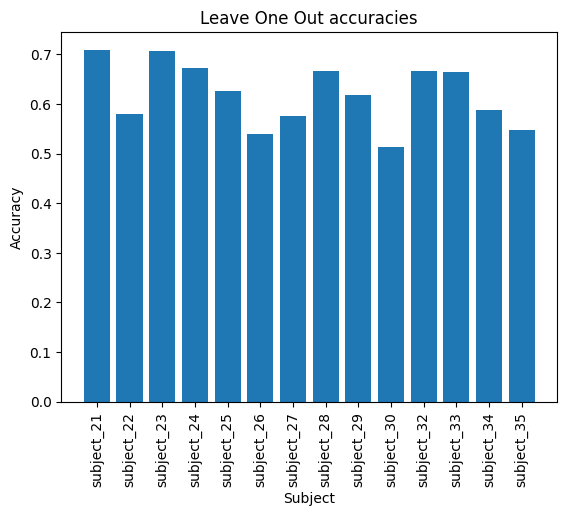

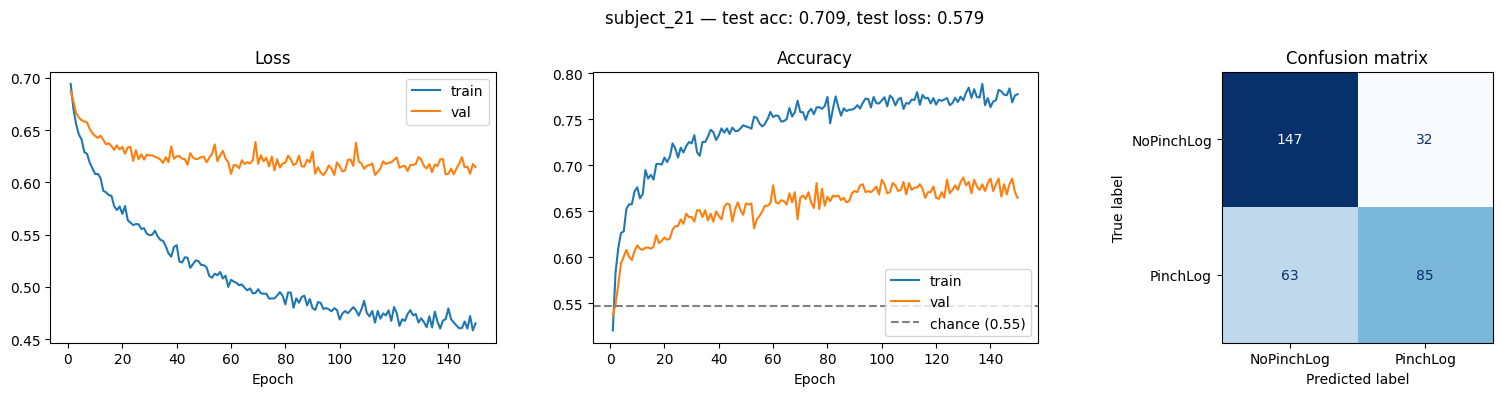

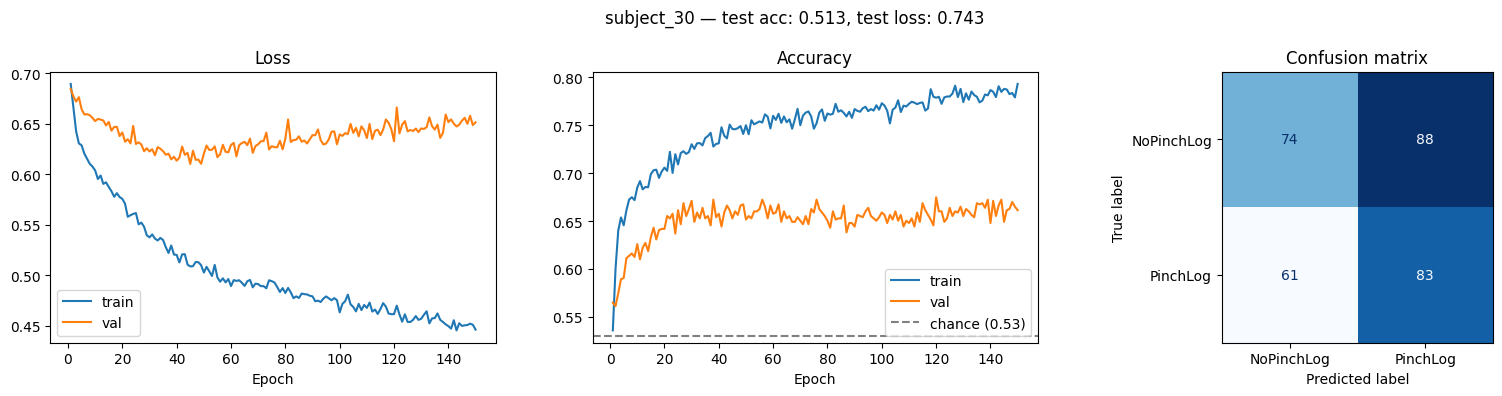

In [10]:
def plot_leave_one_out_run(results):
    plt.bar(results.keys(), [result['result']['test_accuracy'] for result in results.values()])
    plt.xlabel("Subject")
    plt.ylabel("Accuracy")
    plt.title("Leave One Out accuracies")
    plt.xticks(rotation=90)
    plt.show()

    best_subject = max(results, key=lambda k: results[k]['result']['test_accuracy'])
    worst_subject = min(results, key=lambda k: results[k]['result']['test_accuracy'])

    plot_run(results[best_subject]['result'], run_name=best_subject)
    plot_run(results[worst_subject]['result'], run_name=worst_subject)

plot_leave_one_out_run(results_leave_one_out)

### Comparing with hard-negatives

## Multi-Branch GAT-GRU-Transformer

Wang Z and Wang Y (2025)

Input:

In [13]:
def transformer_general(data):
    X_train_idx, X_test_idx, y_train, y_test = train_test_split(np.arange(len(data)), data.metadata.EventType, test_size=.2)
    X_train, X_test = data[X_train_idx], data[X_test_idx]
    out = train_gat_gru_transformer(X_train, y_train, X_test, y_test, sfreq=300.0, epochs=15, batch_size=32, log_wandb=False)
    print("test accuracy:", out["test_accuracy"])
    print(out["confusion_matrix"])
    return out

def transformer_cross_subject(data, leave_out=''):
    train_subjects, test_subjects = train_test_split(data.metadata["subject"].unique().tolist())
    if leave_out != '':
        train_subjects = data.metadata["subject"].unique().tolist()
        train_subjects.remove(leave_out)
        test_subjects = [leave_out]

    print(f"{len(train_subjects)} train subjects, {len(test_subjects)} test subjects")

    train_epochs = query_epochs(data, f"subject in {train_subjects}")
    test_epochs = query_epochs(data, f"subject in {test_subjects}")

    return train_gat_gru_transformer(train_epochs, train_epochs.metadata.EventType, test_epochs, test_epochs.metadata.EventType, sfreq=300.0, epochs=15, batch_size=32, log_wandb=False, lr=1e-4), test_epochs.metadata

def transformer_cross_session(data):
    train_epochs = query_epochs(data, f"session == 'session_1'")
    test_epochs = query_epochs(data, f"session == 'session_2'")

    return train_gat_gru_transformer(train_epochs, train_epochs.metadata.EventType, test_epochs, test_epochs.metadata.EventType, sfreq=300.0, epochs=15, batch_size=32, log_wandb=False, lr=1e-4), test_epochs.metadata

def transformer_leave_one_out(data):
    results = {}
    for subject in data.metadata["subject"].unique().tolist():
        result, metadata = transformer_cross_subject(data, leave_out=subject)
        results[subject] = {
            'result': result,
            'test_metadata': metadata
        }
    return results

transformer_general_run = run_cached("transformer_general_run", lambda: transformer_general(filtered_epochs_scaled))
transformer_cross_session_run = run_cached("transformer_cross_session_run", lambda: transformer_cross_session(filtered_epochs_scaled))
transformer_leave_one_out_run = run_cached("transformer_leave_one_out_run", lambda: transformer_leave_one_out(filtered_epochs_scaled))
transformer_leave_one_out_gaze_run = run_cached("transformer_leave_one_out_gaze_run", lambda: transformer_leave_one_out(filtered_epochs_gaze_scaled))
transformer_leave_one_out_hinted_run = run_cached("transformer_leave_one_out_hinted_run", lambda: transformer_leave_one_out(filtered_epochs_hinted_scaled))
transformer_leave_one_out_ignored_run = run_cached("transformer_leave_one_out_ignored_run", lambda: transformer_leave_one_out(filtered_epochs_ignored_scaled))

[transformer_general_run] forced recompute, running...
[model] 99,362 parameters on cuda | 20 ch x 601 samples @ 300 Hz | 2 classes | graph density 0.39
epoch    1/15 | train 0.6857/0.5635 | val 0.6788/0.5710 | 2.2s
epoch   10/15 | train 0.4987/0.8099 | val 0.7178/0.6420 | 1.3s
epoch   15/15 | train 0.4428/0.8457 | val 0.7625/0.6534 | 1.3s

test accuracy 0.6223 | macro-F1 0.6132 | best epoch 11
              precision    recall  f1-score   support

  NoPinchLog     0.6014    0.7629    0.6726       447
    PinchLog     0.6603    0.4769    0.5538       432

    accuracy                         0.6223       879
   macro avg     0.6308    0.6199    0.6132       879
weighted avg     0.6303    0.6223    0.6142       879

test accuracy: 0.6222980659840728
[[341 106]
 [226 206]]
[transformer_cross_session_run] forced recompute, running...
[model] 99,362 parameters on cuda | 20 ch x 601 samples @ 300 Hz | 2 classes | graph density 0.38
epoch    1/15 | train 0.6982/0.5241 | val 0.6904/0.4824 | 1

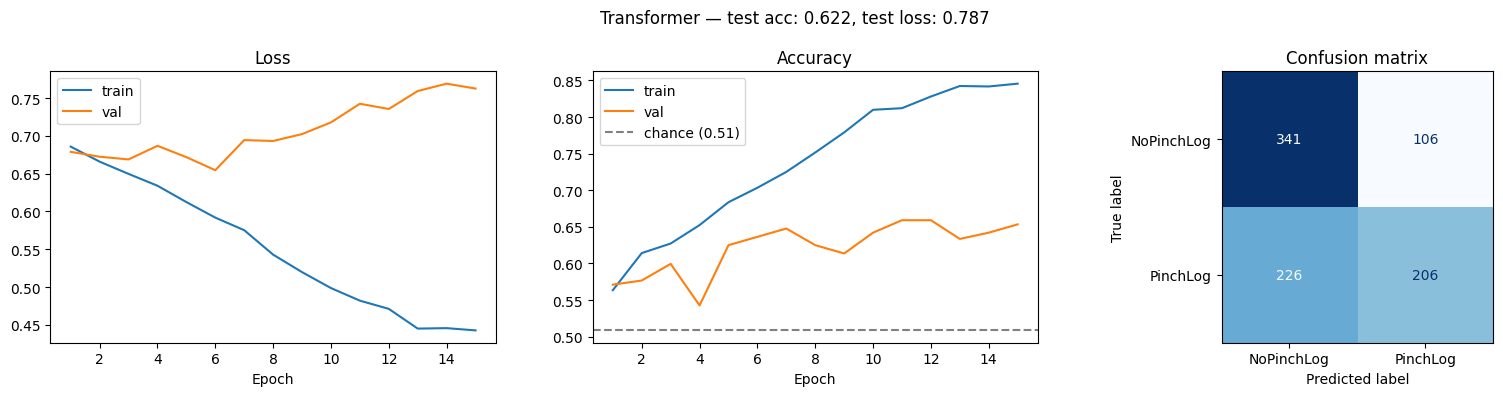

In [14]:
_ = plot_run(transformer_general_run, run_name="Transformer") 

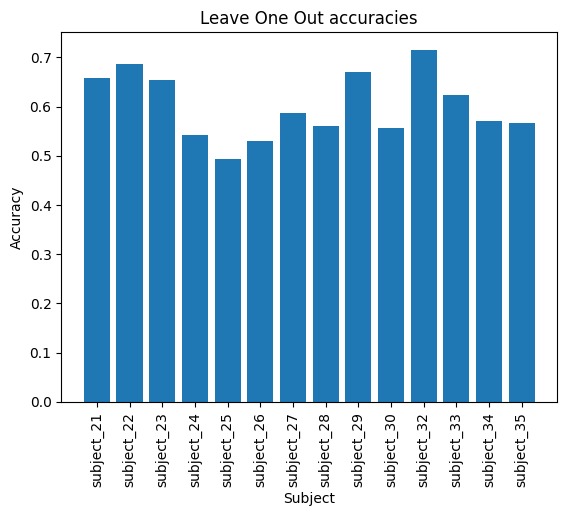

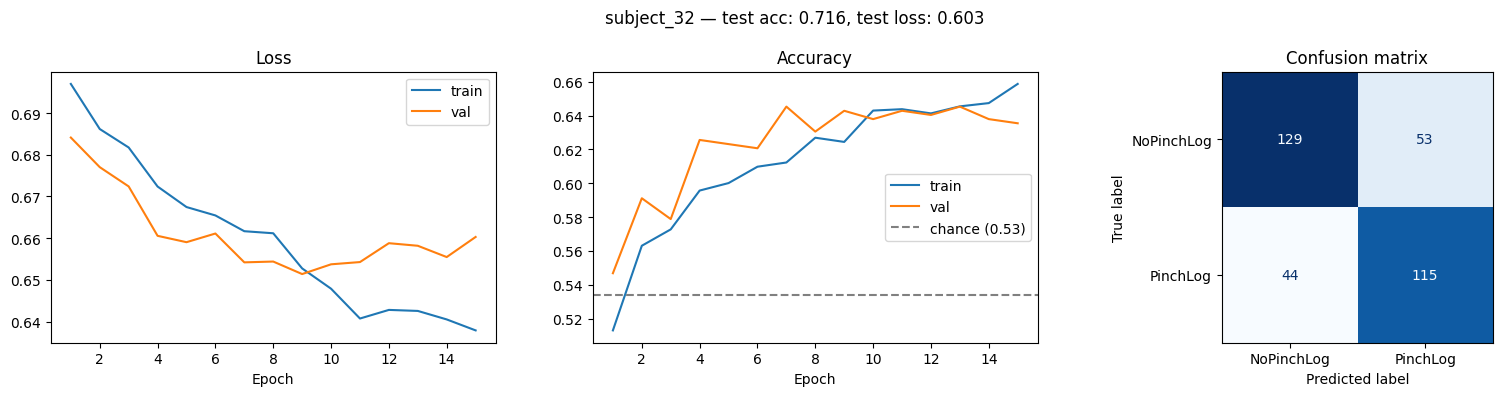

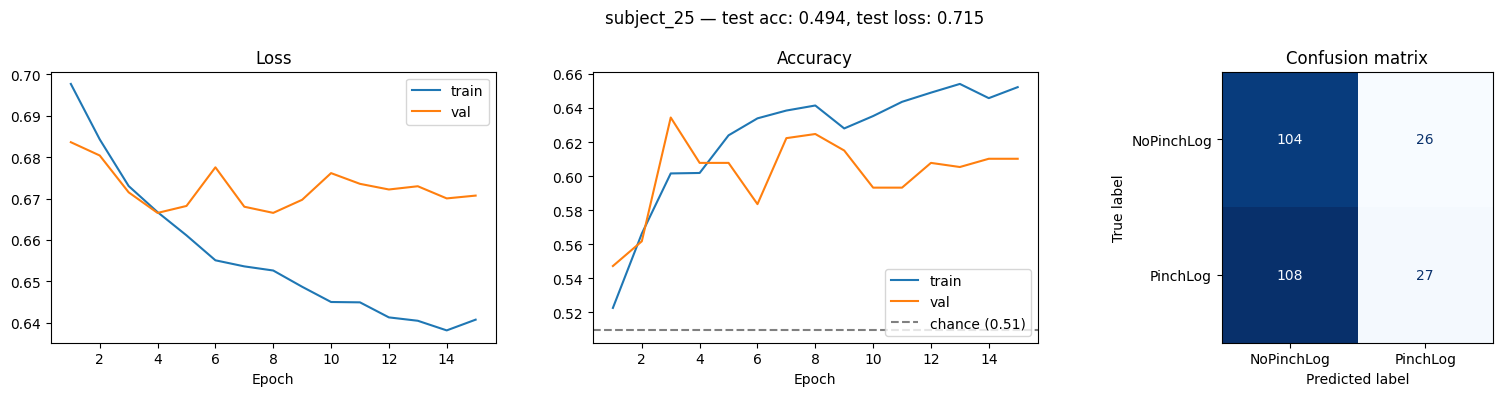

In [15]:
plot_leave_one_out_run(transformer_leave_one_out_run)
# transformer_leave_one_out_run['result']

### Model interpretability (paper section 2.5) — best leave-one-out subject

Runs the interpretability helpers defined in the Multi-Branch GAT-GRU-Transformer cell (`channel_importance`, `band_importance`, `gat_attention`, `plv_report`) on the leave-one-out fold with the highest held-out test accuracy.

In [16]:
best_subject = max(transformer_leave_one_out_run, key=lambda k: transformer_leave_one_out_run[k]['result']['test_accuracy'])
best_result = transformer_leave_one_out_run[best_subject]['result']
model = best_result['model']
ch_names = best_result['ch_names']
classes = best_result['classes']

test_epochs = query_epochs(filtered_epochs_scaled, f"subject in ['{best_subject}']")
lut = {c: i for i, c in enumerate(classes)}
y_enc = np.array([lut[v] for v in test_epochs.metadata.EventType.values])

print(f"best subject: {best_subject} | test accuracy {best_result['test_accuracy']:.4f} | "
      f"macro-F1 {best_result['test_macro_f1']:.4f} | {len(test_epochs)} held-out trials")

best subject: subject_32 | test accuracy 0.7155 | macro-F1 0.7151 | 341 held-out trials


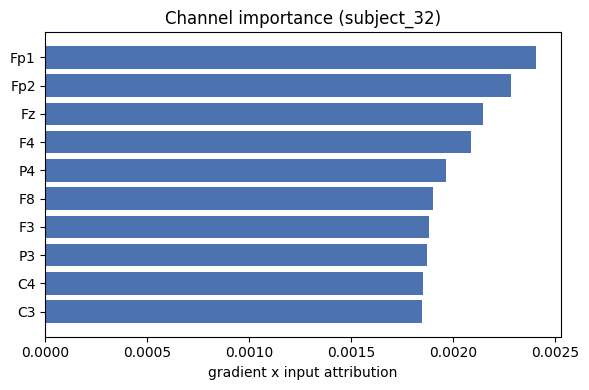

In [17]:
chan_imp = channel_importance(model, test_epochs, y_enc, ch_names, top_k=10)
plt.figure(figsize=(6, 4))
plt.barh([c for c, _ in chan_imp[::-1]], [v for _, v in chan_imp[::-1]], color="#4C72B0")
plt.xlabel("gradient x input attribution")
plt.title(f"Channel importance ({best_subject})")
plt.tight_layout()
plt.show()

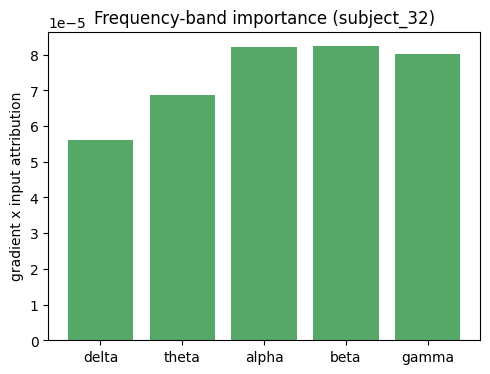

In [18]:
band_imp = band_importance(model, test_epochs, y_enc)
plt.figure(figsize=(5, 4))
plt.bar(list(band_imp.keys()), list(band_imp.values()), color="#55A868")
plt.ylabel("gradient x input attribution")
plt.title(f"Frequency-band importance ({best_subject})")
plt.tight_layout()
plt.show()

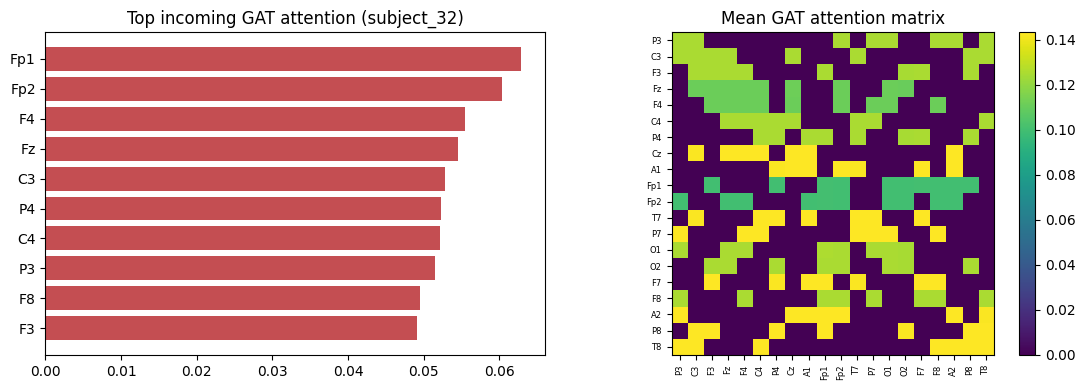

In [19]:
gat_top, gat_att = gat_attention(model, test_epochs, ch_names, top_k=10)
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].barh([c for c, _ in gat_top[::-1]], [v for _, v in gat_top[::-1]], color="#C44E52")
axes[0].set_title(f"Top incoming GAT attention ({best_subject})")

im = axes[1].imshow(gat_att, cmap="viridis")
axes[1].set_xticks(range(len(ch_names))); axes[1].set_xticklabels(ch_names, rotation=90, fontsize=6)
axes[1].set_yticks(range(len(ch_names))); axes[1].set_yticklabels(ch_names, fontsize=6)
axes[1].set_title("Mean GAT attention matrix")
fig.colorbar(im, ax=axes[1], fraction=0.046)
plt.tight_layout()
plt.show()

In [20]:
plv = plv_report(test_epochs, sfreq=300.0, ch_names=ch_names, bands=("alpha", "beta", "gamma"))
for band, pairs in plv.items():
    print(f"{band}:")
    for a, b, v in pairs[:5]:
        print(f"  {a}-{b}: {v:.3f}")

alpha:
  Fz-F4: 0.718
  F4-Fp2: 0.682
  F3-Fz: 0.615
  Fz-Fp2: 0.594
  Cz-A1: 0.584
beta:
  F3-Fz: 0.618
  Fz-F4: 0.612
  F4-Fp2: 0.588
  Fp2-O1: 0.545
  Fp1-F7: 0.525
gamma:
  F3-Fz: 0.580
  Fp2-O1: 0.548
  Fz-F4: 0.530
  O1-O2: 0.526
  Fp1-F7: 0.510


## Analysing free variables

This chapter highlights differences in classification performance from a free variable standpoint.

In [21]:
results_general_meta

,UnityTimestamp,EventType,EventName,Severity,ExperimentName,ExperimentIndex,timestamp,stream,Eye,State,...,GazeDirection.z,HeadPosition.x,HeadPosition.y,HeadPosition.z,HeadForward.x,HeadForward.y,HeadForward.z,sample,subject,session
1046,2026-08-27T14:44:33.0654174+02:00,PinchLog,PINCH_STIMULUS,MESSAGE,Experiment8 (Experiments.ExperimentStatic),8,1003.984136,Experiment.VIBE.GameEventStream,None,None,...,0.996569,0.047186,1.100862,-0.051890,-0.001757,-0.031197,0.999512,359388,subject_21,session_1
50117,NaN,NoPinchLog,NaN,NaN,NaN,8,731.149085,NaN,None,None,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,266560,subject_34,session_2
25475,2026-09-01T11:00:22.1164249+02:00,PinchLog,PINCH_STIMULUS,MESSAGE,Experiment5 (Experiments.ExperimentStatic),5,514.964064,Experiment.VIBE.GameEventStream,None,None,...,0.992462,0.012319,1.096893,0.037560,0.025000,-0.030975,0.999207,202020,subject_27,session_2
27271,2026-09-08T10:50:22.9062380+02:00,PinchLog,PINCH_STIMULUS,MESSAGE,Experiment7 (Experiments.ExperimentStatic),7,801.613566,Experiment.VIBE.GameEventStream,None,None,...,0.998672,-0.020911,1.110263,0.015037,-0.077292,0.196700,0.977412,292679,subject_28,session_1
47927,2026-09-16T15:16:54.0955164+02:00,PinchLog,PINCH_STIMULUS,MESSAGE,Experiment6 (Experiments.ExperimentRandom),6,717.867082,Experiment.VIBE.GameEventStream,None,None,...,0.945763,0.168792,1.117956,0.089735,0.021722,-0.008458,0.999728,258564,subject_34,session_1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
44448,NaN,NoPinchLog,NaN,NaN,NaN,1,38.132744,NaN,None,None,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,58512,subject_33,session_2
20985,NaN,NoPinchLog,NaN,NaN,NaN,11,1281.375634,NaN,None,None,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,471743,subject_26,session_1
36299,NaN,NoPinchLog,NaN,NaN,NaN,6,587.711116,NaN,None,None,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,223024,subject_30,session_2
10047,NaN,NoPinchLog,NaN,NaN,NaN,5,596.942778,NaN,None,None,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,223749,subject_24,session_1


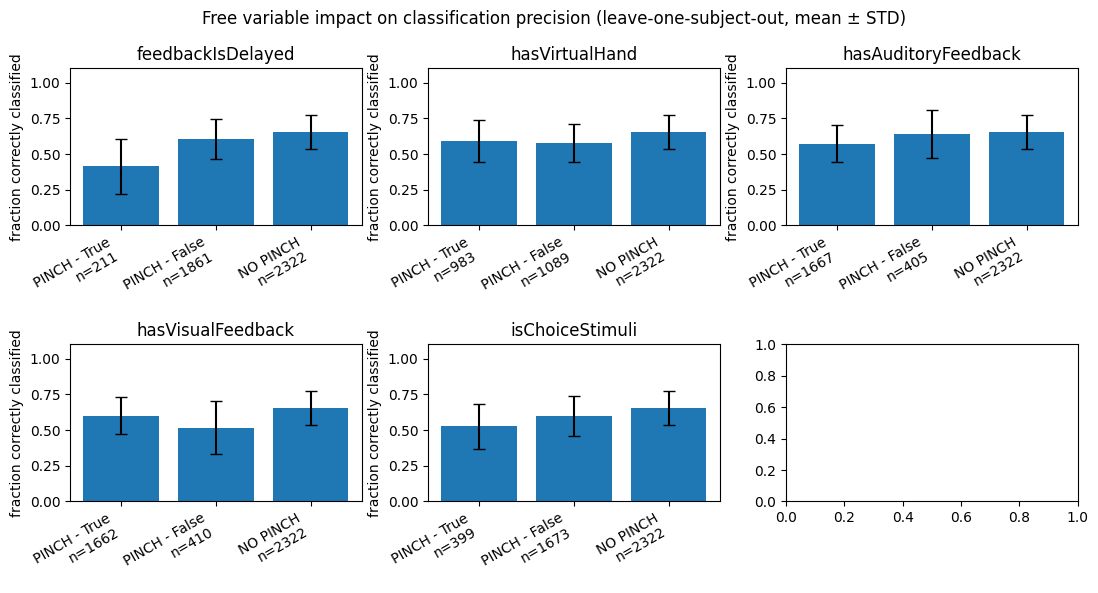

In [22]:
FREE_VARS = ['feedbackIsDelayed', 'hasVirtualHand', 'hasAuditoryFeedback', 'hasVisualFeedback', 'isChoiceStimuli']

def _loo_fold_metadata(payload):
    """Attaches y_pred and per-class probability columns to one leave-one-subject-out fold's test metadata."""
    result = payload["result"]
    meta = payload["test_metadata"].copy()
    meta["y_pred"] = result["y_pred"]
    classes = result["classes"]
    for i, c in enumerate(classes):
        meta[f"y_proba_{c}"] = result["y_proba"][:, i]
    meta["proba_true"] = np.where(
        meta["EventType"] == "PinchLog", meta["y_proba_PinchLog"], meta["y_proba_NoPinchLog"]
    )
    return meta

def _hardlabel_precision(metadata, v):
    """Fraction of correctly predicted labels per group, for one free variable."""
    def frac(hit_query, total_query):
        total = len(metadata.query(total_query))
        if total == 0:
            return np.nan, 0
        return len(metadata.query(hit_query)) / total, total

    pinch_true, n_true = frac(
        f"{v} == True & EventType == 'PinchLog' & y_pred == 'PinchLog'",
        f"{v} == True & EventType == 'PinchLog'",
    )
    pinch_false, n_false = frac(
        f"{v} == False & EventType == 'PinchLog' & y_pred == 'PinchLog'",
        f"{v} == False & EventType == 'PinchLog'",
    )
    no_pinch, n_no_pinch = frac(
        "EventType == 'NoPinchLog' & y_pred == 'NoPinchLog'",
        "EventType == 'NoPinchLog'",
    )
    return [pinch_true, pinch_false, no_pinch], [n_true, n_false, n_no_pinch]


def plot_free_variable_comparison_loo(results_leave_one_out, group_stat_fn, ylabel, title, agg="std"):
    """
    Aggregates a per-group statistic (computed per left-out subject via group_stat_fn) across
    leave-one-subject-out folds, and plots the across-fold mean with std/SEM error bars - this
    captures subject-to-subject variability that a single train/test split can't show.
    """
    fig, axes = plt.subplots(2, 3, figsize=(11, 6))
    axes = axes.flatten()

    for i, v in enumerate(FREE_VARS):
        fold_values, fold_ns = [], []
        for payload in results_leave_one_out.values():
            values, ns = group_stat_fn(_loo_fold_metadata(payload), v)
            fold_values.append(values)
            fold_ns.append(ns)

        values = np.array(fold_values, dtype=float)  # (n_folds, 3)
        ns = np.nansum(np.array(fold_ns, dtype=float), axis=0).astype(int)

        means = np.nanmean(values, axis=0)
        stds = np.nanstd(values, axis=0, ddof=1)
        n_folds = np.sum(~np.isnan(values), axis=0)
        errs = stds / np.sqrt(np.maximum(n_folds, 1)) if agg == "sem" else stds
        errs = np.nan_to_num(errs, nan=0.0)

        labels = [f"PINCH - True\nn={ns[0]}", f"PINCH - False\nn={ns[1]}", f"NO PINCH\nn={ns[2]}"]

        axes[i].bar(labels, means, yerr=errs, capsize=4)
        axes[i].set_title(v)
        axes[i].set_ylabel(ylabel)
        axes[i].tick_params(axis="x", rotation=30)
        axes[i].set_ylim((0, 1.1))
        for label in axes[i].get_xticklabels():
            label.set_ha("right")

    fig.suptitle(f"{title} (leave-one-subject-out, mean ± {agg.upper()})")
    fig.tight_layout()
    return fig


_ = plot_free_variable_comparison_loo(
    results_leave_one_out, _hardlabel_precision, ylabel="fraction correctly classified",
    title="Free variable impact on classification precision",
)

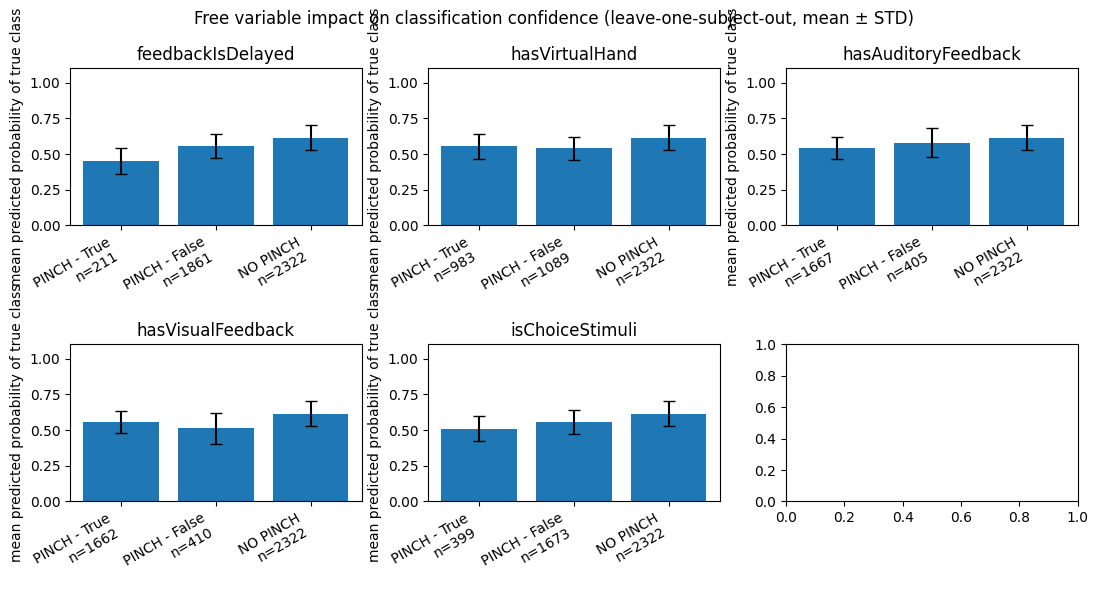

In [23]:
def _mean_true_proba(metadata, v):
    """Mean predicted probability assigned to the true class per group, for one free variable."""
    def mean_and_n(query):
        sub = metadata.query(query)
        if len(sub) == 0:
            return np.nan, 0
        return sub["proba_true"].mean(), len(sub)

    pinch_true, n_true = mean_and_n(f"{v} == True & EventType == 'PinchLog'")
    pinch_false, n_false = mean_and_n(f"{v} == False & EventType == 'PinchLog'")
    no_pinch, n_no_pinch = mean_and_n("EventType == 'NoPinchLog'")
    return [pinch_true, pinch_false, no_pinch], [n_true, n_false, n_no_pinch]


_ = plot_free_variable_comparison_loo(
    results_leave_one_out, _mean_true_proba, ylabel="mean predicted probability of true class",
    title="Free variable impact on classification confidence",
)

## Persist results

In [24]:
for path in sorted(RESULTS_DIR.glob("*.pkl")):
    with open(path, "rb") as fh:
        cached = pickle.load(fh)
    match = "current" if cached.get("data_version") == DATA_VERSION else "stale"
    print(f"{path.stem:30s} data_version={cached.get('data_version')} ({match})")


classify_leave_one_out4        data_version=a4190877a20981c4 (current)
eegnet_cross_session_run       data_version=a4190877a20981c4 (current)
eegnet_cross_subject_run       data_version=a4190877a20981c4 (current)
eegnet_general_run             data_version=a4190877a20981c4 (current)
eegnet_leave_one_out_gaze_run  data_version=a4190877a20981c4 (current)
eegnet_leave_one_out_hinted_run data_version=a4190877a20981c4 (current)
eegnet_leave_one_out_ignored_run data_version=a4190877a20981c4 (current)
eegnet_leave_one_out_run       data_version=a4190877a20981c4 (current)
results_cross_session          data_version=a4190877a20981c4 (current)
results_cross_subject          data_version=a4190877a20981c4 (current)
results_general                data_version=a4190877a20981c4 (current)
results_leave_one_out          data_version=a4190877a20981c4 (current)
results_leave_one_out1         data_version=a4190877a20981c4 (current)
results_leave_one_out2         data_version=a4190877a20981c4 (current)
res